# 02 · Order books, fees and liquidity

As Glosten and Milgrom (1985) show in their study of informed trading, a bid–ask spread can arise from information asymmetry. A discrepancy measured at the midpoint is therefore not a trade available at that price. As Hasbrouck (2007) discusses in *Empirical market microstructure*, trading mechanisms and execution costs must be represented explicitly.

Kalshi returns bids on YES and NO. A NO bid at 0.58 supplies a YES ask at 0.42 with the same quantity. Levels are sorted explicitly, with decimal arithmetic preserving fractional quantities.

In [1]:
from pathlib import Path
import sys, json
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'kalshi_engine/client.py').exists())
if str(root) not in sys.path: sys.path.insert(0, str(root))
import numpy as np
import pandas as pd
from kalshi_engine.client import ROOT
from kalshi_engine.presentation import show_table, show_figure, equation, read
from kalshi_engine.microstructure import Book, FeePolicy, sweep, execution_fee
from kalshi_engine.arbitrage import partition_audit, temperature_payoff_states, coherence, basket, statewise_portfolio
from kalshi_engine.probability import normalise, calibrate, scores, fit_temperature, paired_block_interval
print('Kalshi Microstructure Research | recorded public-data study | no order placement')

Kalshi Microstructure Research | recorded public-data study | no order placement


a_i^Y=1-b_i^N,\qquad a_i^N=1-b_i^Y (2)

s_i=a_i^Y-b_i^Y,\qquad m_i=(a_i^Y+b_i^Y)/2 (3)

I_i=(D_i^b-D_i^a)/(D_i^b+D_i^a) (4)

\widetilde m_i=(a_i^Y D_i^b+b_i^Y D_i^a)/(D_i^b+D_i^a) (5)

two_sided,crossed,bid,ask,spread,midpoint,bid_depth,ask_depth,imbalance,weighted_midpoint
True,False,0.40000,0.42000,0.02000,0.41000,7.25000,4.50000,0.23404,0.41234


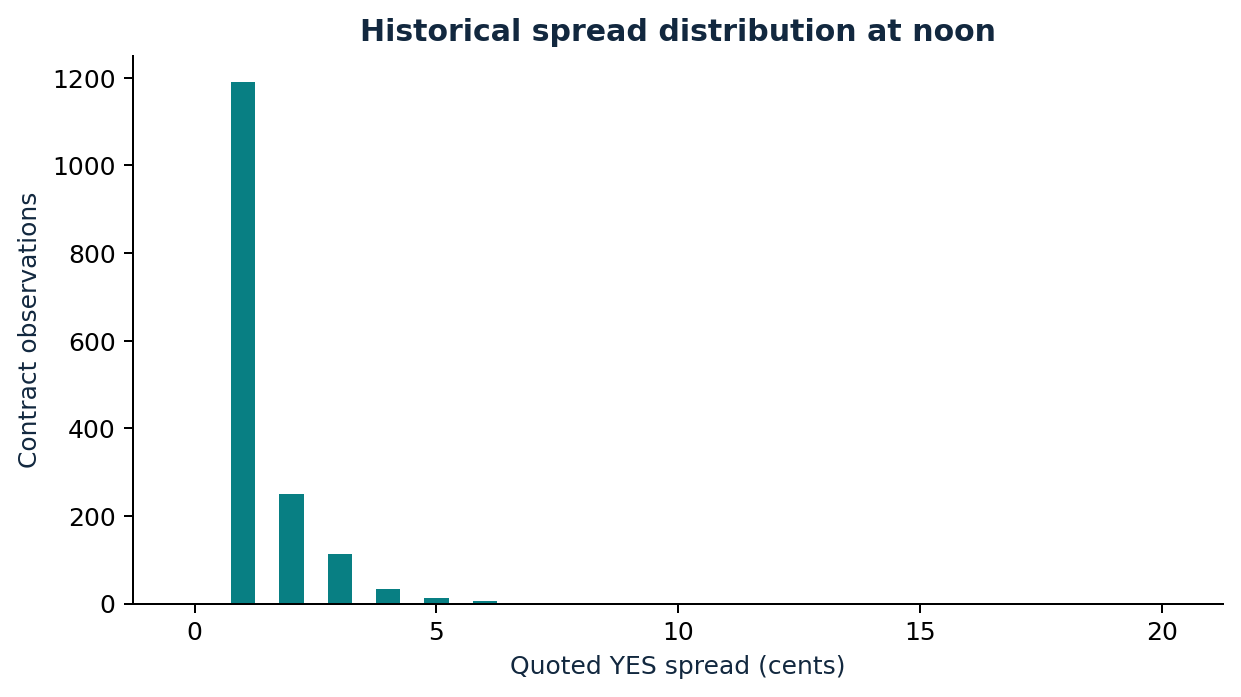

Figure 2. Historical spreads from accepted noon events. Candle-close quotes have no accompanying depth or fill guarantee.

In [2]:
equation(2)
equation(3)
equation(4)
equation(5)
example = Book.from_payload({'yes_dollars':[['0.40','7.25']],'no_dollars':[['0.58','4.50']]})
assert float(example.asks('yes')[0][0])==0.42
show_table(pd.DataFrame([example.metrics()]), 'Table N02.1. Complement reconstruction and displayed-depth metrics.')
show_figure(2)

## Quantity and fee rounding

The current general taker fee is quadratic in price and uses the series multiplier. The rounding guide distinguishes direct-member balance precision from non-direct-member precision and carries rounding overpayment across order fills. Price-level aggregation is not a record of counterparty fill fragmentation; scenario assumptions remain explicit.

balance_precision,one_contract_fee,100_separate_fills_same_order
0.0001,0.01750,1.75000
0.01,0.02000,1.75000


C_i(q)=\sum_{\ell}p_{i\ell}q_{i\ell},\qquad\sum_{\ell}q_{i\ell}=q (6)

f_i=0.07M_i\sum_{\ell}q_{i\ell}p_{i\ell}(1-p_{i\ell}) (7)

f_{\ell}^{net}=\lceil f_{\ell}^{model}\rceil_{10^{-6}}+r_{\ell}-R_{\ell} (8)

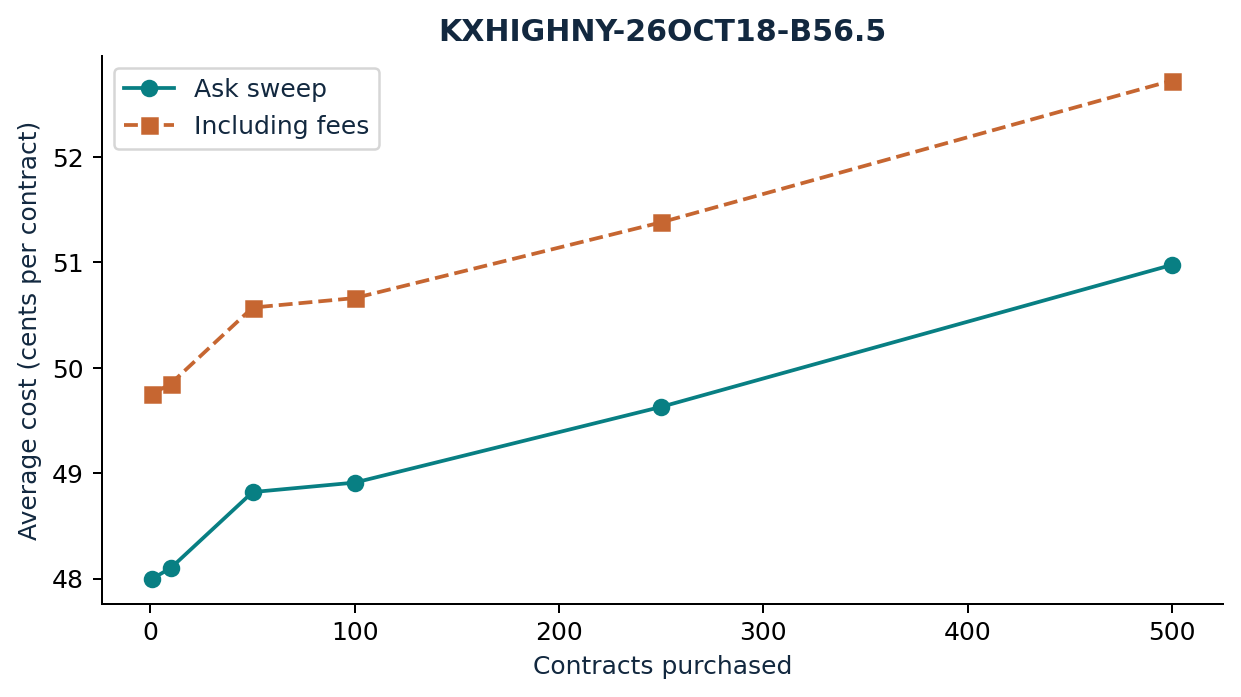

Figure 6. Displayed-depth purchase costs for the final snapshot whose midpoint is nearest 0.50; the selection rule is descriptive and does not use future returns.

In [3]:
from decimal import Decimal
rows=[]
for precision in ['0.0001','0.01']:
    policy=FeePolicy(balance_precision=Decimal(precision))
    rows.append({'balance_precision':precision,'one_contract_fee':float(execution_fee([('0.5','1')],policy)),'100_separate_fills_same_order':float(execution_fee([('0.5','1')]*100,policy))})
show_table(pd.DataFrame(rows), 'Table N02.2. Fee rounding and the order accumulator at a 0.50 price.')
equation(6)
equation(7)
equation(8)
assert not sweep(example,'yes',5)['fillable']
show_figure(6)

## Snapshot imbalance has a limited interpretation

As Cont, Kukanov and Stoikov (2014) describe in *The price impact of order book events*, changes in supply and demand at the best quotes relate to price changes. The present pilot measures displayed depth imbalance from snapshots; it does not reconstruct their event-based order-flow imbalance. Twenty batch responses are too brief to support a forecasting or causal claim.

measure,value
rounds,20
book_snapshots,720
distinct_markets,36
distinct_events,6
start,2026-10-17T20:29:46.177164+00:00
end,2026-10-17T20:32:32.296365+00:00
median_spread,0.01000
median_response_seconds,5.30744
conditional_basket_candidates,0
strict_basket_candidates,0


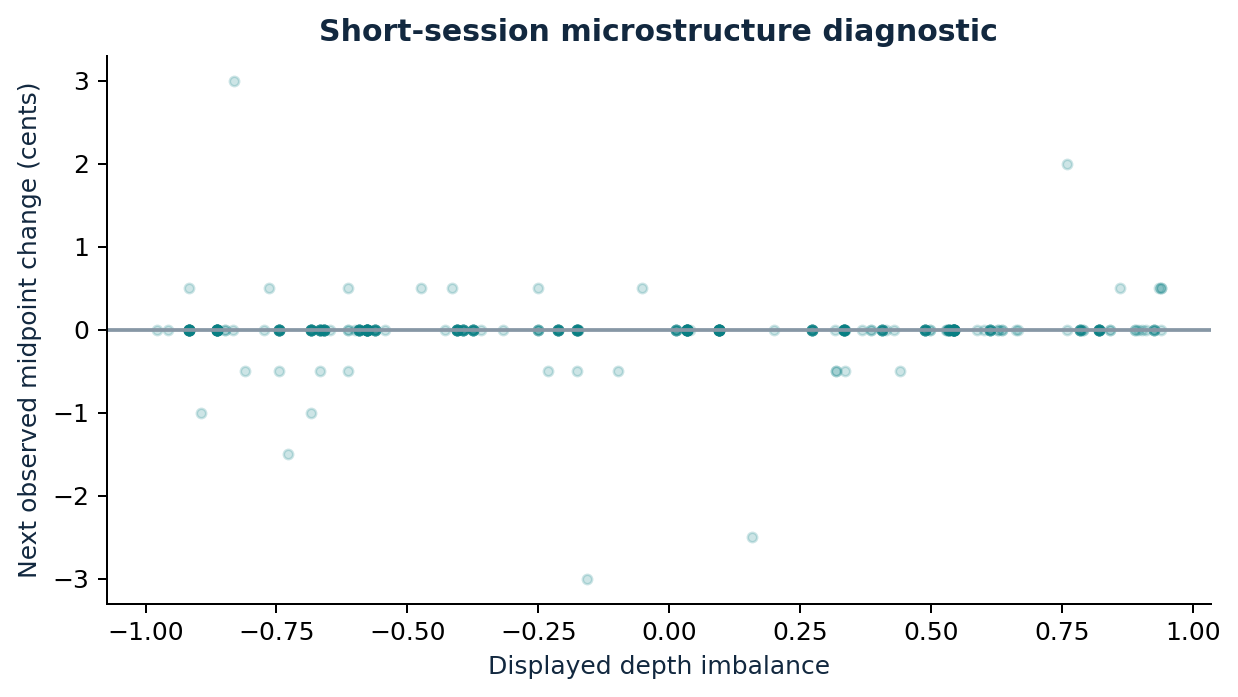

Figure 7. Snapshot imbalance and the next observed midpoint change in the brief live session; these are not order-flow events or independent trading trials.

No per-book exchange timestamp, queue position or market-wide tick history was observed.


In [4]:
live=read('outputs/live-results.json')
show_table(pd.DataFrame({'measure':list(live),'value':list(live.values())}), 'Table N02.3. Live collection summary; spans describe HTTP observation uncertainty.')
show_figure(7)
assert live['book_snapshots']==720
print('No per-book exchange timestamp, queue position or market-wide tick history was observed.')